In [2]:
import pandas as pd
import numpy as np
import joblib

from sklearn.ensemble import RandomForestClassifier

# Đọc dữ liệu đặc trưng chưa chuẩn hóa
X_train = pd.read_csv("../data/processed/X_train.csv")
X_val = pd.read_csv("../data/processed/X_val.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

# Đọc nhãn
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_val = pd.read_csv("../data/processed/y_val.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (396332, 79)
Validation: (98194, 79)
Test: (100117, 79)


In [3]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Huấn luyện mô hình
rf_model.fit(X_train, y_train)

print("Huấn luyện Random Forest thành công!")

Huấn luyện Random Forest thành công!


In [4]:
joblib.dump(
    rf_model,
    "../models/random_forest.pkl"
)

print("Đã lưu Random Forest thành công!")

Đã lưu Random Forest thành công!


In [5]:
# Lấy xác suất giao dịch thuộc lớp gian lận (fraud = 1)
val_probs = rf_model.predict_proba(X_val)[:, 1]

print("5 xác suất dự đoán đầu tiên:")
print(val_probs[:5])

print("\nXác suất nhỏ nhất:", val_probs.min())
print("Xác suất lớn nhất:", val_probs.max())

5 xác suất dự đoán đầu tiên:
[0.00045913 0.00056571 0.00059617 0.08954619 0.00047917]

Xác suất nhỏ nhất: 0.0
Xác suất lớn nhất: 0.9972534309311605


In [6]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.05, 0.96, 0.05)

results = []

for threshold in thresholds:
    y_val_pred = (val_probs >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Predicted_Fraud": y_val_pred.sum()
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score  Predicted_Fraud
      0.05     0.1114  1.0000    0.2005             9691
      0.10     0.1587  1.0000    0.2739             6806
      0.15     0.1973  1.0000    0.3296             5474
      0.20     0.2147  0.9972    0.3533             5017
      0.25     0.2475  0.9889    0.3958             4316
      0.30     0.2873  0.9824    0.4446             3693
      0.35     0.3397  0.9778    0.5042             3109
      0.40     0.4072  0.9630    0.5724             2554
      0.45     0.4604  0.9481    0.6199             2224
      0.50     0.5299  0.9361    0.6767             1908
      0.55     0.5860  0.9213    0.7163             1698
      0.60     0.6339  0.9028    0.7448             1538
      0.65     0.6747  0.8796    0.7637             1408
      0.70     0.7214  0.8583    0.7839             1285
      0.75     0.7752  0.8204    0.7971             1143
      0.80     0.8482  0.7861    0.8160             1001
      0.85     0.9005  0.7370  

In [7]:
best_index = results_df["F1-score"].idxmax()

best_threshold = results_df.loc[
    best_index, "Threshold"
]

print("Ngưỡng tốt nhất:", best_threshold)
print("\nKết quả tương ứng:")
print(results_df.loc[best_index])

Ngưỡng tốt nhất: 0.8

Kết quả tương ứng:
Threshold             0.800000
Precision             0.848152
Recall                0.786111
F1-score              0.815954
Predicted_Fraud    1001.000000
Name: 15, dtype: float64


In [8]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# 1. Dự đoán xác suất gian lận trên tập Test
test_probs = rf_model.predict_proba(X_test)[:, 1]

# 2. Áp dụng ngưỡng đã chọn từ Validation
y_test_pred = (test_probs >= best_threshold).astype(int)

# 3. In ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_test_pred)

# 4. Tính các chỉ số đánh giá
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, digits=4))

# 5. Tính riêng các chỉ số của lớp gian lận
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
pr_auc = average_precision_score(y_test, test_probs)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("PR-AUC:", round(pr_auc, 4))


Classification Report:
              precision    recall  f1-score   support

           0     0.9976    0.9988    0.9982     99037
           1     0.8727    0.7806    0.8240      1080

    accuracy                         0.9964    100117
   macro avg     0.9351    0.8897    0.9111    100117
weighted avg     0.9963    0.9964    0.9963    100117

Precision: 0.8727
Recall: 0.7806
F1-score: 0.824
PR-AUC: 0.8983


In [9]:
# Lưu ngưỡng phân loại tối ưu
with open("../models/random_forest_threshold.txt", "w") as f:
    f.write(str(best_threshold))

print("Đã lưu ngưỡng Random Forest:", best_threshold)

Đã lưu ngưỡng Random Forest: 0.8


In [15]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Tổng hợp các chỉ số đánh giá
evaluation_results = pd.DataFrame({
    "Chỉ số đánh giá": [
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Giá trị": [
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0),
        roc_auc_score(y_test, test_probs),
        average_precision_score(y_test, test_probs)
    ]
})

# Đánh số thứ tự từ 1
evaluation_results.index = range(1, len(evaluation_results) + 1)

# Hiển thị kết quả
print("Kết quả đánh giá mô hình Random Forest:")

display(
    evaluation_results.style
    .format({"Giá trị": "{:.5f}"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center")]}
    ])
)

Kết quả đánh giá mô hình Random Forest:


,Chỉ số đánh giá,Giá trị
1,Precision,0.87267
2,Recall,0.78056
3,F1-Score,0.82405
4,ROC-AUC,0.99807
5,PR-AUC,0.89825


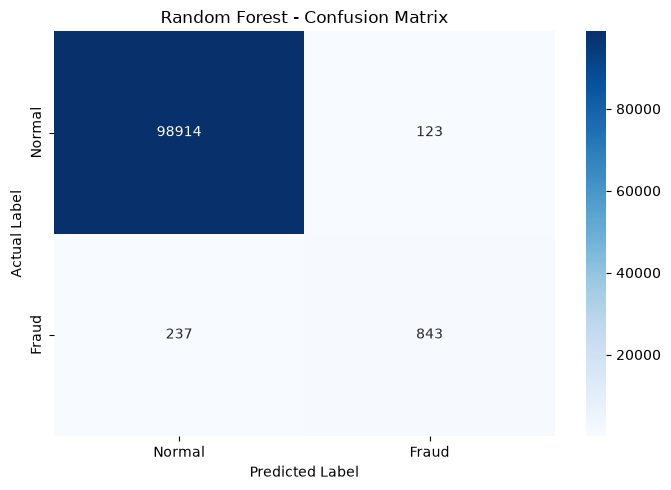

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Vẽ Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

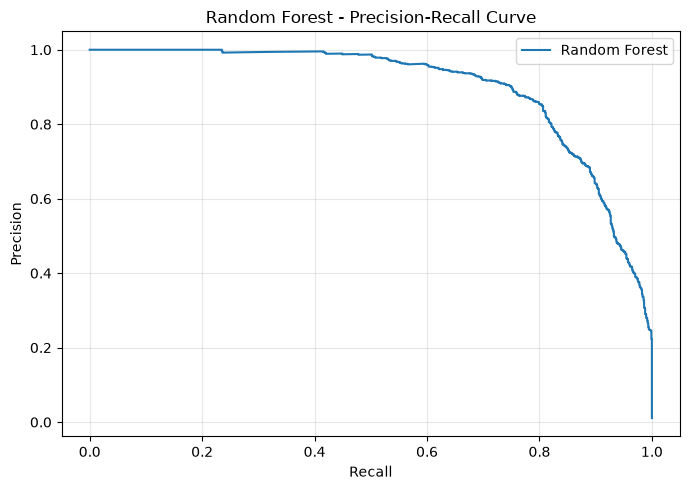

In [12]:
from sklearn.metrics import precision_recall_curve

# Tính Precision và Recall
precision_values, recall_values, _ = precision_recall_curve(
    y_test,
    test_probs
)

# Vẽ Precision-Recall Curve
plt.figure(figsize=(7, 5))

plt.plot(
    recall_values,
    precision_values,
    label="Random Forest"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

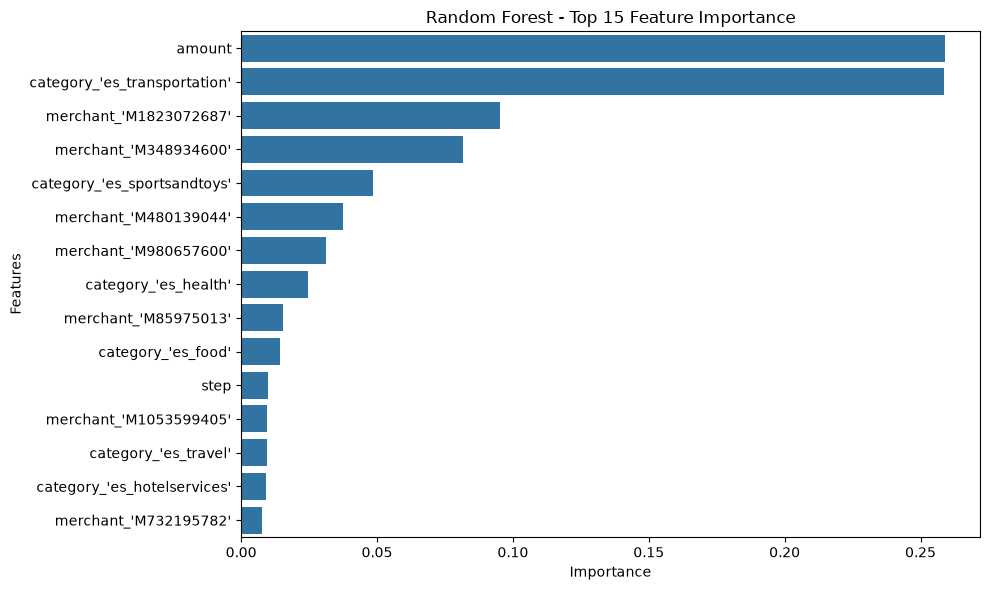

In [13]:
# Random Forest - Feature Importance

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=feature_importance.head(15).values,
    y=feature_importance.head(15).index
)

plt.title("Random Forest - Top 15 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()